# Car Parts — детали автомобиля, Supervisely

Набор деталей находится в `car-parts-and-damage-dataset/Car damages dataset/`: реальные классы определяются по `meta.json` и `classTitle`. Доступен 21 класс деталей.

Аннотации: `File1/ann/*.json`; фото ожидаются в `File1/img/`. Читаются `points.exterior`, внутренние отверстия `points.interior`, размеры `size` и цвета из `meta.json`. Сейчас фото отсутствуют: показывается реальная разметка на сером фоне с явной подписью. Когда фото появятся по ожидаемым путям, они будут отображаться автоматически.

`SPLIT = "all"`. Пример: `CLASS_FILTER = "Front-door"`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "car-parts-and-damage-dataset" / "Car damages dataset"
SPLIT = "all"
N_IMAGES = 4
N_COLS = 2
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
dataset, class_metadata = load_supervisely(DATASET_ROOT)
print("Источник классов:", DATASET_ROOT / "meta.json")
summary = summarize(dataset)


Источник классов: C:\Users\nikita\Desktop\Car_Damage_Detection\datasets\car-parts-and-damage-dataset\Car damages dataset\meta.json
Записей: 998; изображения отсутствуют: 998
Выборки: {'all': 998}
Классы (число меток):
  Back-bumper: 443
  Back-door: 721
  Back-wheel: 865
  Back-window: 1,237
  Back-windshield: 271
  Fender: 935
  Front-bumper: 705
  Front-door: 917
  Front-wheel: 885
  Front-window: 951
  Grille: 577
  Headlight: 914
  Hood: 712
  License-plate: 370
  Mirror: 987
  Quarter-panel: 855
  Rocker-panel: 860
  Roof: 793
  Tail-light: 721
  Trunk: 416
  Windshield: 632


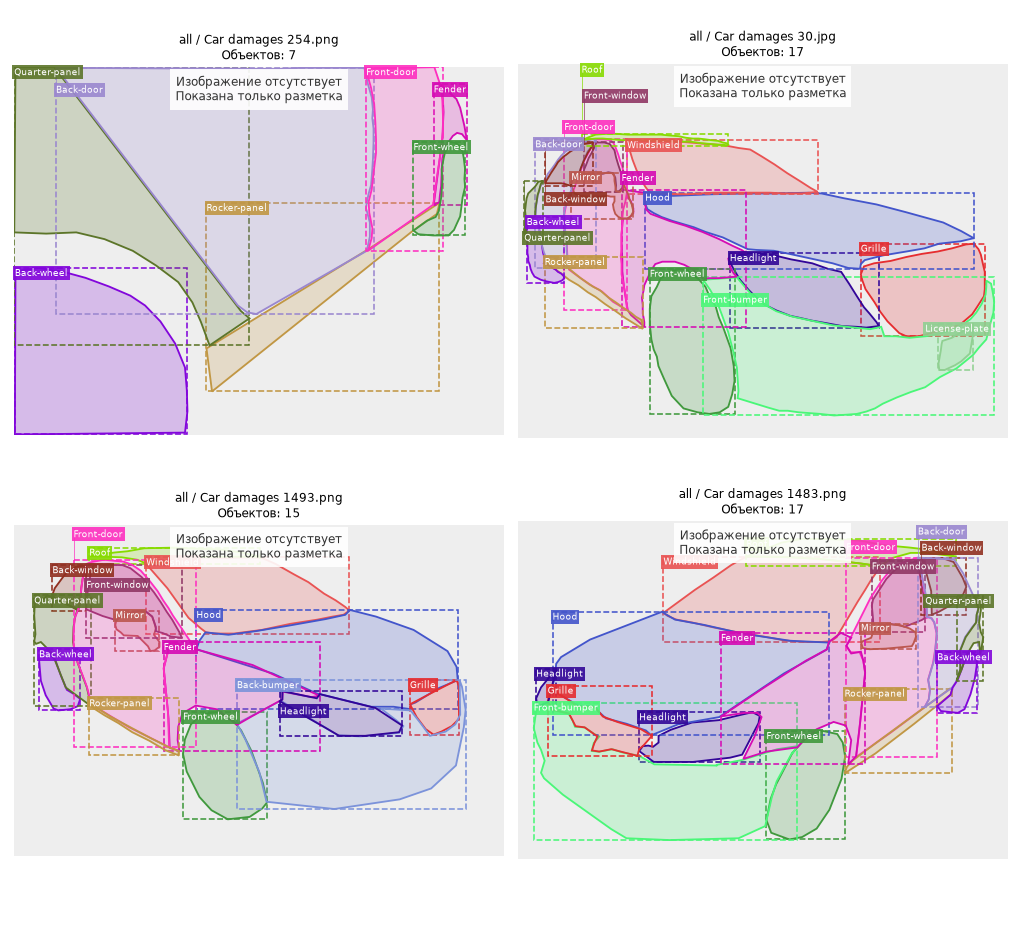

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
